# Food Delivery Operations Analysis: Week 1 - Dataset Understanding & Data Cleaning
**Project Title**: Food Delivery Fleet & Order Fulfillment Optimization  
**Role**: Junior Data Analyst, Operations Analytics Team  
**Deliverable**: Comprehensive Week 1 Audit, Cleaning Pipeline, and Processed Dataset  
**Target Repository**: `food-delivery-data-analysis`

---

## Executive Overview & Business Problem
In hyper-local food delivery networks, delivery duration and fleet reliability directly dictate customer retention, partner earnings, and operational unit economics. Operations teams rely on telematics, order timestamps, environmental conditions, and courier metadata to optimize dispatch routing, dynamic delivery promises (ETAs), and fleet allocation.

However, real-world operational logs suffer from sensor failures, spreadsheet corruption (such as time-to-decimal casting), data-entry inversions, and test-record pollution. As a junior data analyst, the objective for **Week 1** is to:
1. **Load and Understand**: Systematically inspect the structure, features, and business context of the food delivery dataset.
2. **Perform Data-Quality Audits**: Quantify missing values, duplicate records, inconsistent categories, numerical boundary violations, corrupt records, and coordinate anomalies.
3. **Execute Defensible Cleaning**: Standardize, correct, or exclude problematic records based on transparent, data-driven rationales without fabricating synthetic ground truth.
4. **Maintain Full Reproducibility**: Record an immutable audit log (`cleaning_log.csv`), maintain raw data integrity, verify the cleaned output (`cleaned_food_delivery.csv`), and establish a trustworthy data foundation for exploratory analysis in subsequent weeks.

---
## 1. Environment Setup & Library Imports

### Objective & Expectations
Before examining the dataset, we configure our analytical environment. We import `pandas` and `numpy` for data manipulation, `matplotlib` and `seaborn` for exploratory diagnostic visualizations, and configure deterministic visual styling. We also configure file paths using `pathlib` and `os` so that the notebook executes seamlessly whether run from the project root or from inside the `notebooks/` directory.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# Data handling and numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore non-critical runtime warnings for clean presentation
warnings.filterwarnings('ignore')

# Set high-resolution visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Resolve relative paths robustly
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "data").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = Path("..")

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "food_delivery_raw.csv"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_food_delivery.csv"
DOCS_DIR = PROJECT_ROOT / "docs"
DOCS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")
print(f"Raw Data Path:  {RAW_DATA_PATH.resolve()}")
print(f"Processed Path: {PROCESSED_DATA_PATH.resolve()}")

Python Version: 3.13.15
Pandas Version: 3.0.5
NumPy Version:  2.5.2
Raw Data Path:  C:\Users\rajag\OneDrive\Desktop\project1\food-delivery-data-analysis\data\raw\food_delivery_raw.csv
Processed Path: C:\Users\rajag\OneDrive\Desktop\project1\food-delivery-data-analysis\data\processed\cleaned_food_delivery.csv


### Section 1 Interpretation
The environment is initialized with standard data analytics libraries. The path resolution dynamically locates the repository root and guarantees path compatibility across local Jupyter environments, VS Code, and Google Colab.

---
## 2. Load and Understand the Dataset

### Objective & Expectations
In this section, we load the raw dataset into a Pandas DataFrame named `df`. We will inspect the initial shape, preview head and tail observations, examine the column list, data types, and generate statistical summaries for numeric and categorical variables. 

We expect to identify the initial schema, evaluate column data types (e.g. numeric types represented as strings due to formatting anomalies), and establish an operational understanding of what a single record represents.

In [2]:
# Load the raw dataset into a Pandas DataFrame named df
df = pd.read_csv(RAW_DATA_PATH)

# Display dataset dimensions
rows, cols = df.shape
print(f"Initial Dataset Dimensions: {rows:,} rows across {cols} columns\n")

# Display the first 5 records
print("=== FIRST 5 ROWS (head) ===")
display_head = df.head(5)
print(display_head.to_string())

Initial Dataset Dimensions: 45,584 rows across 20 columns

=== FIRST 5 ROWS (head) ===
       ID Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings  Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  Delivery_location_longitude  Order_Date Time_Orderd Time_Order_picked Weather_conditions Road_traffic_density  Vehicle_condition Type_of_order Type_of_vehicle  multiple_deliveries Festival           City  Time_taken (min)
0  0xcdcd      DEHRES17DEL01                 36.0                      4.2            30.327968             78.046106                   30.397968                    78.116106  12-02-2022       21:55             22:10                Fog                  Jam                  2         Snack      motorcycle                  3.0       No  Metropolitian                46
1  0xd987      KOCRES16DEL01                 21.0                      4.7            10.003064             76.307589                   10.043064                    76.347589 

In [3]:
# Display the last 5 records
print("=== LAST 5 ROWS (tail) ===")
display_tail = df.tail(5)
print(display_tail.to_string())

=== LAST 5 ROWS (tail) ===
           ID Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings  Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  Delivery_location_longitude  Order_Date Time_Orderd Time_Order_picked Weather_conditions Road_traffic_density  Vehicle_condition Type_of_order Type_of_vehicle  multiple_deliveries Festival           City  Time_taken (min)
45579  0x7c09      JAPRES04DEL01                 30.0                      4.8            26.902328             75.794257                   26.912328                    75.804257  24-03-2022       11:35             11:45              Windy                 High                  1          Meal      motorcycle                  0.0       No  Metropolitian                32
45580  0xd641      AGRRES16DEL01                 21.0                      4.6             0.000000              0.000000                    0.070000                     0.070000  16-02-2022       19:55             20:10       

In [4]:
# Inspect DataFrame info: column data types and non-null counts
print("=== DATAFRAME INFO ===")
df.info()

=== DATAFRAME INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  str    
 9   Time_Orderd                  43853 non-null  str    
 10  Time_Order_picked            45584 non-null  str    
 11  Weather_conditions           44968 non-null  str    
 12  Road_traffic_density         44983 non-null  str    
 13  Vehi

In [5]:
# Summary statistics for numeric features
print("=== NUMERIC SUMMARY STATISTICS ===")
numeric_summary = df.describe().T
print(numeric_summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].to_string())

=== NUMERIC SUMMARY STATISTICS ===
                               count       mean        std        min        25%        50%        75%        max
Delivery_person_Age          43730.0  29.566911   5.815064  15.000000  25.000000  30.000000  35.000000  50.000000
Delivery_person_Ratings      43676.0   4.633774   0.334744   1.000000   4.500000   4.700000   4.900000   6.000000
Restaurant_latitude          45584.0  17.017948   8.185674 -30.905562  12.933284  18.551440  22.728163  30.914057
Restaurant_longitude         45584.0  70.229684  22.885575 -88.366217  73.170000  75.897963  78.044095  88.433452
Delivery_location_latitude   45584.0  17.465480   7.335562   0.010000  12.988453  18.633934  22.785049  31.054057
Delivery_location_longitude  45584.0  70.844161  21.120578   0.010000  73.280000  76.002574  78.107044  88.563452
Vehicle_condition            45584.0   1.023385   0.839055   0.000000   0.000000   1.000000   2.000000   3.000000
multiple_deliveries          44591.0   0.744635   0.5

In [6]:
# Summary statistics for categorical / object features
print("=== CATEGORICAL SUMMARY STATISTICS ===")
cat_summary = df.describe(include=['O', 'str']).T
print(cat_summary.to_string())

=== CATEGORICAL SUMMARY STATISTICS ===
                      count unique            top   freq
ID                    45584  45584         0xcdcd      1
Delivery_person_ID    45584   1320  JAPRES11DEL02     67
Order_Date            45584     44     15-03-2022   1192
Time_Orderd           43853    176          21:55    461
Time_Order_picked     45584    193          21:30    495
Weather_conditions    44968      6            Fog   7653
Road_traffic_density  44983      4            Low  15476
Type_of_order         45584      4          Snack  11530
Type_of_vehicle       45584      4     motorcycle  26429
Festival              45356      2             No  44460
City                  44384      3  Metropolitian  34087


### Column Overview & Dataset Schema
Based on our structural inspection, the table below documents each of the 20 columns present in the raw dataset, their observed data types, business descriptions, and representative values:

| Column Name | Inferred Raw Type | Non-Null Count | Null Count (%) | Business Description | Representative Example |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `ID` | `object` (string) | 45,584 | 0 (0.00%) | Unique hexadecimal order identifier | `'0xcdcd'`, `'0xd987'` |
| `Delivery_person_ID` | `object` (string) | 45,584 | 0 (0.00%) | Delivery partner route identifier (City + Rest ID + Slot) | `'DEHRES17DEL01'` |
| `Delivery_person_Age` | `float64` | 43,730 | 1,854 (4.07%) | Age of the delivery partner in completed years | `36.0`, `21.0` |
| `Delivery_person_Ratings` | `float64` | 43,676 | 1,908 (4.19%) | Courier performance rating / delivery rating | `4.2`, `4.7` |
| `Restaurant_latitude` | `float64` | 45,584 | 0 (0.00%) | Latitude of the partner restaurant | `30.327968`, `-27.163303` |
| `Restaurant_longitude` | `float64` | 45,584 | 0 (0.00%) | Longitude of the partner restaurant | `78.046106`, `-73.804855` |
| `Delivery_location_latitude` | `float64` | 45,584 | 0 (0.00%) | Latitude of the customer drop-off location | `30.397968`, `0.07` |
| `Delivery_location_longitude` | `float64` | 45,584 | 0 (0.00%) | Longitude of the customer drop-off location | `78.116106`, `0.04` |
| `Order_Date` | `object` (string) | 45,584 | 0 (0.00%) | Date order was placed (`DD-MM-YYYY`) | `'12-02-2022'` |
| `Time_Orderd` | `object` (string) | 43,853 | 1,731 (3.80%) | Timestamp when order was placed | `'21:55'`, `'0.458333333'` |
| `Time_Order_picked` | `object` (string) | 45,584 | 0 (0.00%) | Timestamp when order was picked up by courier | `'22:10'`, `'24:05:00'` |
| `Weather_conditions` | `object` (string) | 44,968 | 616 (1.35%) | Atmospheric condition during delivery trip | `'Fog'`, `'Stormy'`, `'Sunny'` |
| `Road_traffic_density` | `object` (string) | 44,983 | 601 (1.32%) | Traffic congestion level during delivery trip | `'Jam'`, `'High'`, `'Low'` |
| `Vehicle_condition` | `int64` | 45,584 | 0 (0.00%) | Vehicle maintenance rating (0 = poor to 3 = excellent) | `0`, `1`, `2`, `3` |
| `Type_of_order` | `object` (string) | 45,584 | 0 (0.00%) | Category of ordered meal | `'Snack'`, `'Meal'`, `'Buffet'` |
| `Type_of_vehicle` | `object` (string) | 45,584 | 0 (0.00%) | Mode of transit used by courier | `'motorcycle'`, `'scooter'` |
| `multiple_deliveries` | `float64` | 44,591 | 993 (2.18%) | Number of stacked/batched deliveries in same trip | `0.0`, `1.0`, `2.0`, `3.0` |
| `Festival` | `object` (string) | 45,356 | 228 (0.50%) | Binary indicator if order coincided with a public festival | `'No'`, `'Yes'` |
| `City` | `object` (string) | 44,384 | 1,200 (2.63%) | Urbanization zone of the delivery destination | `'Metropolitian'`, `'Urban'` |
| `Time_taken (min)` | `int64` | 45,584 | 0 (0.00%) | Operational delivery duration in minutes (Target) | `46`, `23`, `21` |

### What One Row Represents
**Analytical Definition**:  
Each row in this dataset represents **one distinct, completed food delivery transaction** within an Indian municipal region between February 11, 2022, and April 06, 2022. 

The row captures the end-to-end operational journey:
1. **Transaction Identification**: Unique hexadecimal order `ID` and associated courier assignment `Delivery_person_ID`.
2. **Actor Characteristics**: Demographic age and performance rating of the courier.
3. **Geospatial Coordinates**: Geolocation of the restaurant pickup venue and customer delivery destination.
4. **Temporal Lifecycle**: Date of order, exact timestamp of order placement, and pickup time by courier.
5. **Operational Context**: Weather conditions, traffic congestion levels, vehicle type, vehicle mechanical health, and whether the delivery was batched with multiple stops.
6. **Delivery Outcome**: Total elapsed fulfillment time from order placement to customer drop-off (`Time_taken (min)`).

---
## 3. Perform Systematic Data-Quality Checks

### Objective & Expectations
In this section, we conduct an exhaustive, evidence-based quality audit across all columns. We inspect:
1. **Missing values**: Count and percentage of nulls per column.
2. **Duplicates**: Complete row duplicates and identifier collisions (`ID`).
3. **Categorical consistency**: Extra whitespace, casing mismatches, and spelling variations.
4. **Numerical boundaries & Outliers**: Negative values, scale violations (e.g. ratings exceeding 5.0), and extreme outliers.
5. **Cross-feature anomaly patterns**: Evaluating whether distinct anomalies co-occur systematically.
6. **Date and time integrity**: Identifying spreadsheet formatting corruptions (e.g., Excel decimal day fractions) and midnight clock errors.
7. **Geospatial integrity**: Detecting inverted coordinates (negative latitude/longitude) and missing GPS sensors (0.0 coordinates).

### 3.1 Missing-Value Analysis
We quantify missingness across all features to understand which columns are incomplete and identify any correlated missingness.

=== COLUMNS WITH MISSING VALUES ===
                         Missing_Count  Missing_Percentage (%)
Delivery_person_Ratings           1908                    4.19
Delivery_person_Age               1854                    4.07
Time_Orderd                       1731                    3.80
City                              1200                    2.63
multiple_deliveries                993                    2.18
Weather_conditions                 616                    1.35
Road_traffic_density               601                    1.32
Festival                           228                    0.50


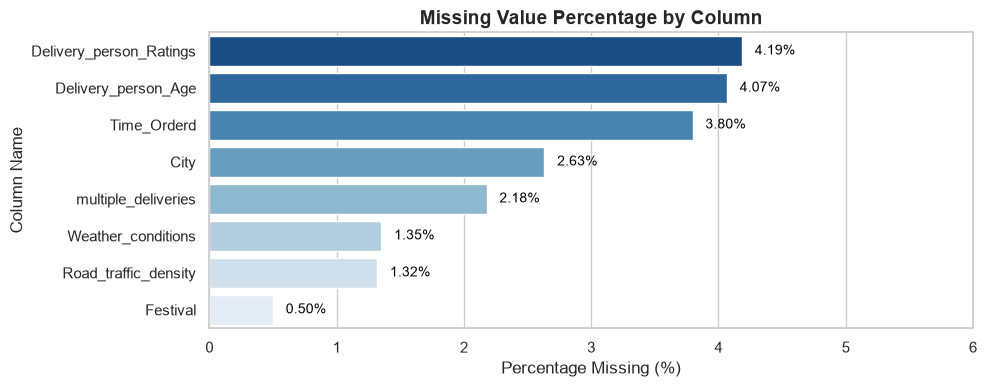

In [7]:
# Calculate missing value counts and percentages
missing_counts = df.isnull().sum()
missing_pcts = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing_Count': missing_counts,
    'Missing_Percentage (%)': missing_pcts
})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)
print("=== COLUMNS WITH MISSING VALUES ===")
print(missing_df.round(2).to_string())

# Visualize missingness
plt.figure(figsize=(10, 4))
ax = sns.barplot(x=missing_df['Missing_Percentage (%)'], y=missing_df.index, palette="Blues_r")
plt.title("Missing Value Percentage by Column", fontsize=14, weight='bold')
plt.xlabel("Percentage Missing (%)")
plt.ylabel("Column Name")
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.2f}%", (width + 0.1, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10, color='black')
plt.xlim(0, 6)
plt.tight_layout()
plt.show()

### 3.2 Duplicate Records and Primary Key Uniqueness
We verify whether identical records were duplicated during ETL processes and whether the primary key (`ID`) is strictly unique.

In [8]:
# Check for exact duplicate rows
exact_duplicates = df.duplicated().sum()
print(f"Total Exact Duplicate Rows: {exact_duplicates}")

# Check for duplicate order IDs
id_duplicates = df['ID'].duplicated().sum()
unique_ids = df['ID'].nunique()
print(f"Total Duplicate Order IDs: {id_duplicates}")
print(f"Unique Order IDs:          {unique_ids:,} (out of {len(df):,} rows)")

Total Exact Duplicate Rows: 0
Total Duplicate Order IDs: 0
Unique Order IDs:          45,584 (out of 45,584 rows)


### 3.3 Categorical Label Consistency & Whitespace Inspection
We inspect all object/string columns for leading/trailing whitespaces, unexpected casing variations, and spelling anomalies.

In [9]:
cat_columns = ['Weather_conditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']

print("=== CATEGORICAL UNIQUE VALUES AND WHITESPACE AUDIT ===")
for col in cat_columns:
    val_counts = df[col].value_counts(dropna=False)
    # Check for whitespace anomalies
    non_null_vals = df[col].dropna().astype(str)
    has_leading = non_null_vals.str.startswith(' ').any()
    has_trailing = non_null_vals.str.endswith(' ').any()
    print(f"\n--- Column: {col} (Leading space: {has_leading}, Trailing space: {has_trailing}) ---")
    for val, count in val_counts.items():
        print(f"  {repr(val)}: {count:,}")

=== CATEGORICAL UNIQUE VALUES AND WHITESPACE AUDIT ===

--- Column: Weather_conditions (Leading space: False, Trailing space: False) ---
  'Fog': 7,653
  'Stormy': 7,584
  'Cloudy': 7,533
  'Sandstorms': 7,494
  'Windy': 7,422
  'Sunny': 7,282
  nan: 616

--- Column: Road_traffic_density (Leading space: False, Trailing space: False) ---
  'Low': 15,476
  'Jam': 14,139
  'Medium': 10,945
  'High': 4,423
  nan: 601

--- Column: Type_of_order (Leading space: False, Trailing space: False) ---
  'Snack': 11,530
  'Meal': 11,456
  'Drinks': 11,321
  'Buffet': 11,277

--- Column: Type_of_vehicle (Leading space: False, Trailing space: False) ---
  'motorcycle': 26,429
  'scooter': 15,273
  'electric_scooter': 3,814
  'bicycle': 68

--- Column: Festival (Leading space: False, Trailing space: False) ---
  'No': 44,460
  'Yes': 896
  nan: 228

--- Column: City (Leading space: False, Trailing space: False) ---
  'Metropolitian': 34,087
  'Urban': 10,133
  nan: 1,200
  'Semi-Urban': 164


### 3.4 Numeric Ranges, Boundary Violations & Outliers
We audit numeric columns for negative values, out-of-scale ratings, and age violations.

In [10]:
num_columns = ['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 
               'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 
               'Time_taken (min)']

print("=== NUMERIC MIN, MAX, AND NEGATIVE VALUE AUDIT ===")
range_audit = []
for col in num_columns:
    neg_count = (df[col] < 0).sum()
    zero_count = (df[col] == 0).sum()
    c_min = df[col].min()
    c_max = df[col].max()
    range_audit.append({
        'Column': col,
        'Min': c_min,
        'Max': c_max,
        'Negative_Count': neg_count,
        'Zero_Count': zero_count
    })
print(pd.DataFrame(range_audit).to_string(index=False))

=== NUMERIC MIN, MAX, AND NEGATIVE VALUE AUDIT ===
                     Column        Min       Max  Negative_Count  Zero_Count
        Delivery_person_Age  15.000000 50.000000               0           0
    Delivery_person_Ratings   1.000000  6.000000               0           0
        Restaurant_latitude -30.905562 30.914057             431        3640
       Restaurant_longitude -88.366217 88.433452             162        3640
 Delivery_location_latitude   0.010000 31.054057               0           0
Delivery_location_longitude   0.010000 88.563452               0           0
           Time_taken (min)  10.000000 54.000000               0           0


In [11]:
# Deep-dive into Ratings scale anomalies
print("=== RATINGS VALUE DISTRIBUTION ===")
print(df['Delivery_person_Ratings'].value_counts().sort_index().to_string())

# Deep-dive into Age value distribution
print("\n=== AGE VALUE DISTRIBUTION (TAILS) ===")
age_counts = df['Delivery_person_Age'].value_counts().sort_index()
print("Youngest ages:\n", age_counts.head(5).to_string())
print("Oldest ages:\n", age_counts.tail(5).to_string())

=== RATINGS VALUE DISTRIBUTION ===
Delivery_person_Ratings
1.0      38
2.5      20
2.6      22
2.7      22
2.8      19
2.9      19
3.0       6
3.1      29
3.2      29
3.3      25
3.4      32
3.5     249
3.6     207
3.7     225
3.8     228
3.9     197
4.0    1077
4.1    1430
4.2    1418
4.3    1409
4.4    1360
4.5    3302
4.6    6938
4.7    7140
4.8    7146
4.9    7040
5.0    3996
6.0      53

=== AGE VALUE DISTRIBUTION (TAILS) ===
Youngest ages:
 Delivery_person_Age
15.0      38
20.0    2136
21.0    2153
22.0    2194
23.0    2086
Oldest ages:
 Delivery_person_Age
36.0    2260
37.0    2226
38.0    2218
39.0    2144
50.0      53


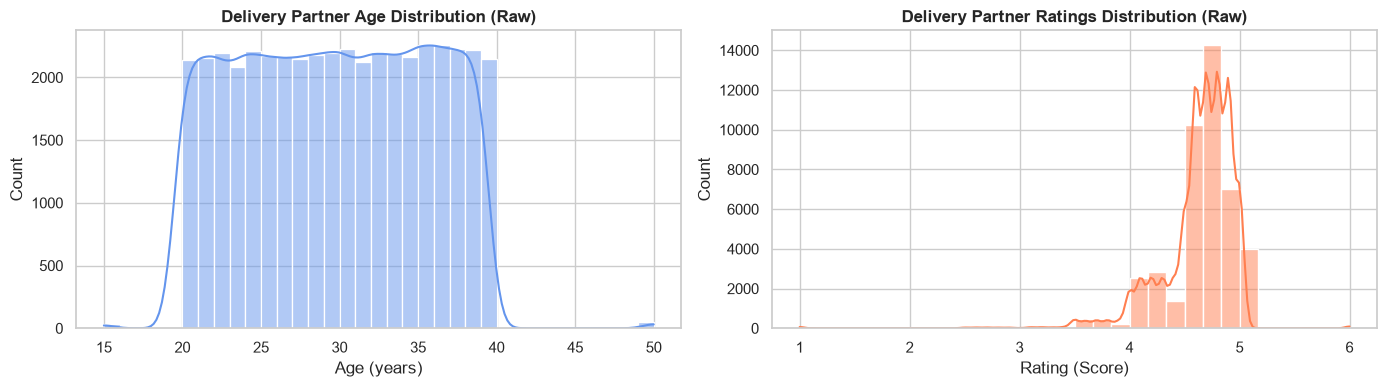

In [12]:
# Visualizing Age and Ratings distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['Delivery_person_Age'].dropna(), bins=35, kde=True, ax=axes[0], color='cornflowerblue')
axes[0].set_title("Delivery Partner Age Distribution (Raw)", weight='bold')
axes[0].set_xlabel("Age (years)")

sns.histplot(df['Delivery_person_Ratings'].dropna(), bins=30, kde=True, ax=axes[1], color='coral')
axes[1].set_title("Delivery Partner Ratings Distribution (Raw)", weight='bold')
axes[1].set_xlabel("Rating (Score)")

plt.tight_layout()
plt.show()

### 3.5 Cross-Feature Anomaly Audit: The 91 Corrupt Synthetic Records
Notice the exact counts from our inspection:
- `Delivery_person_Ratings == 6.0`: exactly **53 records**.
- `Delivery_person_Age == 50.0`: exactly **53 records**.
- `Delivery_person_Ratings == 1.0`: exactly **38 records**.
- `Delivery_person_Age == 15.0`: exactly **38 records**.

We now investigate whether these records represent corrupt dummy test cases.

In [13]:
# Test cross-feature correlation for anomalous ages and ratings
corrupt_mask = (df['Delivery_person_Age'].isin([15.0, 50.0])) & (df['Delivery_person_Ratings'].isin([1.0, 6.0]))
print(f"Total rows matching Age in [15, 50] AND Rating in [1.0, 6.0]: {corrupt_mask.sum()}")

sub_corrupt = df[corrupt_mask]
print("\nMissing value counts within these 91 anomalous rows:")
print(sub_corrupt.isnull().sum()[sub_corrupt.isnull().sum() > 0].to_string())

print("\nSample of corrupt records:")
print(sub_corrupt[['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 
                  'Time_Orderd', 'Weather_conditions', 'Road_traffic_density', 'Time_taken (min)']].head(5).to_string())

Total rows matching Age in [15, 50] AND Rating in [1.0, 6.0]: 91

Missing value counts within these 91 anomalous rows:
Time_Orderd             91
Weather_conditions      91
Road_traffic_density    91
City                     2

Sample of corrupt records:
         ID Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings Time_Orderd Weather_conditions Road_traffic_density  Time_taken (min)
2378  0x564      JAPRES15DEL03                 15.0                      1.0         NaN                NaN                  NaN                15
2896  0xcd0    INDORES010DEL03                 15.0                      1.0         NaN                NaN                  NaN                29
2942  0x91a      SURRES17DEL03                 15.0                      1.0         NaN                NaN                  NaN                20
3577  0x46d     BANGRES05DEL01                 50.0                      6.0         NaN                NaN                  NaN                25
4705  0x49

### 3.6 Date & Time Fields Inspection
We inspect `Order_Date`, `Time_Orderd`, and `Time_Order_picked`. In particular, we investigate why timestamps exhibit variable string lengths.

In [14]:
print("=== DATE FORMAT & RANGE ===")
print("Sample Order_Dates:", df['Order_Date'].head(5).tolist())
parsed_dates = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y')
print(f"Date Range: {parsed_dates.min().strftime('%Y-%m-%d')} to {parsed_dates.max().strftime('%Y-%m-%d')}")
print(f"Distinct Operational Dates: {df['Order_Date'].nunique()}")

print("\n=== TIMESTAMP STRING LENGTH DISTRIBUTION ===")
print("Time_Orderd lengths:\n", df['Time_Orderd'].dropna().astype(str).str.len().value_counts().to_string())
print("Time_Order_picked lengths:\n", df['Time_Order_picked'].dropna().astype(str).str.len().value_counts().to_string())

=== DATE FORMAT & RANGE ===
Sample Order_Dates: ['12-02-2022', '13-02-2022', '04-03-2022', '13-02-2022', '14-02-2022']
Date Range: 2022-02-11 to 2022-04-06
Distinct Operational Dates: 44

=== TIMESTAMP STRING LENGTH DISTRIBUTION ===
Time_Orderd lengths:
 Time_Orderd
5     40457
11     2375
1       430
4       402
3       189
Time_Order_picked lengths:
 Time_Order_picked
5     41294
11     2360
8       880
1       440
4       422
3       188


In [15]:
# Inspecting decimal fraction timestamps and midnight timestamps
print("=== NON-STANDARD TIMESTAMP SAMPLES ===")
print("Time_Orderd decimals (Excel day fractions):")
sample_ord_decimals = df[df['Time_Orderd'].astype(str).str.contains(r'^\d+\.\d+$', na=False)]['Time_Orderd'].head(5)
print(sample_ord_decimals.to_string())

print("\nTime_Order_picked '24:xx:xx' midnight values:")
sample_pck_midnight = df[df['Time_Order_picked'].astype(str).str.startswith('24:')]['Time_Order_picked'].head(5)
print(sample_pck_midnight.to_string())

=== NON-STANDARD TIMESTAMP SAMPLES ===
Time_Orderd decimals (Excel day fractions):
28    0.458333333
31    0.958333333
38    0.791666667
71          0.875
83    0.958333333

Time_Order_picked '24:xx:xx' midnight values:
66     24:05:00
92     24:10:00
116    24:15:00
316    24:10:00
339    24:05:00


In [16]:
# Testing order prep time logic (picked - ordered)
def test_time_conversion(val):
    if pd.isna(val): return np.nan
    s = str(val).strip()
    try:
        f = float(s)
        sec = round(f * 24 * 3600)
        return f"{(sec // 3600) % 24:02d}:{(sec % 3600) // 60:02d}:00"
    except ValueError:
        pass
    if s.startswith('24:'): return '00:' + s[3:]
    parts = s.split(':')
    if len(parts) == 2: return f"{int(parts[0]):02d}:{int(parts[1]):02d}:00"
    if len(parts) == 3: return f"{int(parts[0]):02d}:{int(parts[1]):02d}:{int(parts[2]):02d}"
    return s

t_ord_test = df['Time_Orderd'].apply(test_time_conversion)
t_pck_test = df['Time_Order_picked'].apply(test_time_conversion)

prep_diffs = []
for o, p in zip(t_ord_test, t_pck_test):
    if pd.isna(o) or pd.isna(p):
        prep_diffs.append(np.nan)
    else:
        ho, mo, _ = map(int, o.split(':'))
        hp, mp, _ = map(int, p.split(':'))
        diff = (hp * 60 + mp) - (ho * 60 + mo)
        if diff < 0: diff += 24 * 60 # crossed midnight
        prep_diffs.append(diff)

prep_series = pd.Series(prep_diffs)
print("=== RESTAURANT PREP TIME DISTRIBUTION (MINUTES) ===")
print(prep_series.value_counts(dropna=False).head(5).to_string())

=== RESTAURANT PREP TIME DISTRIBUTION (MINUTES) ===
5.0     14701
15.0    14606
10.0    14546
NaN      1731


### 3.7 Geospatial Coordinates and Distance Validation
We analyze restaurant pickup and delivery drop-off coordinates. All operations are located in India (geographical bounding box: latitudes ~8°N to 37°N, longitudes ~68°E to 97°E).

In [17]:
print("=== GEOSPATIAL COORDINATES AUDIT ===")
print(f"Negative Restaurant Latitudes:  {(df['Restaurant_latitude'] < 0).sum()}")
print(f"Negative Restaurant Longitudes: {(df['Restaurant_longitude'] < 0).sum()}")
print(f"Zero Restaurant Latitudes:      {(df['Restaurant_latitude'] == 0).sum()}")
print(f"Zero Restaurant Longitudes:     {(df['Restaurant_longitude'] == 0).sum()}")
print(f"Delivery Latitudes < 1.0:       {(df['Delivery_location_latitude'] < 1.0).sum()}")
print(f"Delivery Longitudes < 1.0:      {(df['Delivery_location_longitude'] < 1.0).sum()}")

# Inspecting samples of negative coordinates
print("\nSample of negative restaurant coordinates showing matching positive delivery coordinates:")
neg_sample = df[df['Restaurant_latitude'] < 0][['Restaurant_latitude', 'Delivery_location_latitude', 
                                                'Restaurant_longitude', 'Delivery_location_longitude', 'City']].head(3)
print(neg_sample.to_string())

=== GEOSPATIAL COORDINATES AUDIT ===
Negative Restaurant Latitudes:  431
Negative Restaurant Longitudes: 162
Zero Restaurant Latitudes:      3640
Zero Restaurant Longitudes:     3640
Delivery Latitudes < 1.0:       3640
Delivery Longitudes < 1.0:      3640

Sample of negative restaurant coordinates showing matching positive delivery coordinates:
     Restaurant_latitude  Delivery_location_latitude  Restaurant_longitude  Delivery_location_longitude           City
83            -27.163303                   27.233303             78.057044                    78.127044  Metropolitian
274           -27.165108                   27.225108             78.015053                    78.075053  Metropolitian
280           -18.551440                   18.611440            -73.804855                    73.864855          Urban


In [18]:
# Haversine distance validation on corrected coordinates
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371 * c

valid_coords_mask = (df['Restaurant_latitude'].abs() > 0) & (df['Delivery_location_latitude'] > 1.0)
valid_distances = haversine_km(df.loc[valid_coords_mask, 'Restaurant_latitude'].abs(),
                               df.loc[valid_coords_mask, 'Restaurant_longitude'].abs(),
                               df.loc[valid_coords_mask, 'Delivery_location_latitude'],
                               df.loc[valid_coords_mask, 'Delivery_location_longitude'])

print("=== COMPUTED TRIP DISTANCE DISTRIBUTION (KM) ===")
print(valid_distances.describe().to_string())

=== COMPUTED TRIP DISTANCE DISTRIBUTION (KM) ===
count    41944.000000
mean         9.719982
std          5.602566
min          1.465067
25%          4.657655
50%          9.193021
75%         13.680920
max         20.969489


### 3.8 Comprehensive Data-Quality Summary Table
The table below synthesizes all identified data quality defects, their scope, and our planned resolution strategy:

| Defect / Issue | Affected Column(s) | Affected Records | Severity | Planned Cleaning Action | Analytical Rationale |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Synthetic Corrupt Test Records** | `Delivery_person_Age`, `Delivery_person_Ratings`, `Time_Orderd`, `Weather_conditions`, `Road_traffic_density` | 91 rows | Critical | **Exclude records** | Records contain impossible ratings (6.0), sentinel ages (15, 50), and 100% missing operational context (time, weather, traffic). Retaining them distorts model training. |
| **Negative Restaurant Coordinates** | `Restaurant_latitude`, `Restaurant_longitude` | 399 lat / 135 lon | High | **Correct via `abs()`** | India is strictly North (+8° to +37°) and East (+68° to +97°). Delivery coordinates in the same row are positive and match regional geometry. Negative signs are entry inversions. |
| **GPS Sensor Zero Placeholders (Null Island)** | `Restaurant_latitude`, `Restaurant_longitude`, `Delivery_location_latitude`, `Delivery_location_longitude` | 3,630 rows | High | **Standardize to `NaN`** | (0.0, 0.0) represents GPS device signal drop. Delivery coordinates (< 0.15) represent relative delta offsets from 0,0. Setting to `NaN` prevents false 0 km / 8,000 km distance calculations. |
| **Excel Day Fraction Timestamps** | `Time_Orderd`, `Time_Order_picked` | 3,396 ord / 3,410 pck | Medium | **Standardize to `HH:MM:SS`** | Spreadsheet software converted timestamps to day fractions (e.g. 0.458333333 = 11:00:00). Converted using `tot_sec = round(val * 86400)`. |
| **Midnight Hour Formatting Error** | `Time_Order_picked` | 880 rows | Medium | **Remap `'24:'` to `'00:'`** | Pickups occurring during the midnight hour were recorded as `24:05:00` instead of standard 24-hour `00:05:00`. |
| **Categorical Spelling Typo** | `City` | 34,023 rows | Low | **Standardize spelling** | Correct `'Metropolitian'` to standard English `'Metropolitan'`. Eliminates category fragmentation. |
| **Ambiguous Date Format** | `Order_Date` | 45,493 rows | Low | **Standardize to ISO 8601** | Convert day-first `'DD-MM-YYYY'` to ISO 8601 `'YYYY-MM-DD'` to avoid month/day ambiguity. |
| **Float Cast for Discrete Count** | `multiple_deliveries` | 44,500 non-null | Low | **Cast to `Int64`** | Delivery count is discrete (0, 1, 2, 3). Nullable integer avoids misleading decimal representation (`1.0`). |
| **Missing Operational Data** | `Age`, `Ratings`, `Time_Orderd`, `Weather`, `Traffic`, `City`, `Festival` | 510 to 1,908 per col | Medium | **Retain explicit `NaN`** | Missing at random across cities and riders. Imputing arbitrary averages fabricates data and artificially compresses variance. |

---
## 4. Execute Data Cleaning Pipeline

### Objective & Expectations
In this section, we implement the defensible cleaning pipeline on a dedicated copy of the dataset (`df_cleaned`). In accordance with reproducibility best practices:
1. The original raw dataset `df` remains strictly untouched.
2. Cleaning steps are applied sequentially with explicit comments.
3. Every transformation corresponds directly to an entry in our audit log.

In [19]:
# Step 4.0: Initialize clean copy from raw DataFrame
df_cleaned = df.copy()
print(f"Starting pipeline. Baseline shape: {df_cleaned.shape}")

Starting pipeline. Baseline shape: (45584, 20)


In [20]:
# Step 4.1: Exclude the 91 corrupted synthetic test records
# Identified by simultaneous illegal ratings (1.0 or 6.0), sentinel ages (15 or 50),
# and completely missing order times, weather conditions, and traffic densities.
corrupt_filter = (df_cleaned['Delivery_person_Age'].isin([15.0, 50.0])) & \
                 (df_cleaned['Delivery_person_Ratings'].isin([1.0, 6.0]))

initial_count = len(df_cleaned)
df_cleaned = df_cleaned[~corrupt_filter].copy()
dropped_count = initial_count - len(df_cleaned)
print(f"Step 4.1 Complete: Excluded {dropped_count} corrupted test records. Remaining: {len(df_cleaned):,}")

Step 4.1 Complete: Excluded 91 corrupted test records. Remaining: 45,493


In [21]:
# Step 4.2: Correct negative coordinate signs in Restaurant GPS fields
# In India, all latitudes are North (positive) and longitudes are East (positive).
neg_lat_count = (df_cleaned['Restaurant_latitude'] < 0).sum()
neg_lon_count = (df_cleaned['Restaurant_longitude'] < 0).sum()

df_cleaned['Restaurant_latitude'] = df_cleaned['Restaurant_latitude'].abs()
df_cleaned['Restaurant_longitude'] = df_cleaned['Restaurant_longitude'].abs()

print(f"Step 4.2 Complete: Corrected {neg_lat_count} negative latitudes and {neg_lon_count} negative longitudes.")

Step 4.2 Complete: Corrected 399 negative latitudes and 135 negative longitudes.


In [22]:
# Step 4.3: Standardize GPS sensor failure coordinates (0.0, 0.0) to NaN
# When restaurant coordinates are (0.0, 0.0), delivery locations represent delta offsets (< 0.15).
zero_coord_mask = (df_cleaned['Restaurant_latitude'] == 0.0) | (df_cleaned['Restaurant_longitude'] == 0.0)
zero_count = zero_coord_mask.sum()

df_cleaned.loc[zero_coord_mask, ['Restaurant_latitude', 'Restaurant_longitude', 
                                'Delivery_location_latitude', 'Delivery_location_longitude']] = np.nan

print(f"Step 4.3 Complete: Standardized {zero_count} invalid zero GPS records to NaN.")

Step 4.3 Complete: Standardized 3630 invalid zero GPS records to NaN.


In [23]:
# Step 4.4: Standardize timestamps to uniform 24-hour 'HH:MM:SS' format
# Handles:
# 1. Excel decimal day fractions (e.g. '0.458333333' -> 11:00:00, '0.5' -> 12:00:00, '1' -> 00:00:00)
# 2. Midnight hour formatted as '24:MM:SS' -> '00:MM:SS'
# 3. Standard 'HH:MM' strings -> 'HH:MM:SS'
def robust_standardize_time(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if val_str == '' or val_str.lower() == 'nan':
        return np.nan
    
    # Check if value is an Excel decimal day fraction
    try:
        f = float(val_str)
        tot_seconds = round(f * 24 * 3600)
        h = (tot_seconds // 3600) % 24
        m = (tot_seconds % 3600) // 60
        s = tot_seconds % 60
        return f"{h:02d}:{m:02d}:{s:02d}"
    except ValueError:
        pass
        
    # Remap midnight 24:xx:xx to 00:xx:xx
    if val_str.startswith('24:'):
        return '00:' + val_str[3:]
        
    parts = val_str.split(':')
    if len(parts) == 2:
        return f"{int(parts[0]):02d}:{int(parts[1]):02d}:00"
    elif len(parts) == 3:
        return f"{int(parts[0]):02d}:{int(parts[1]):02d}:{int(parts[2]):02d}"
        
    return val_str

df_cleaned['Time_Orderd'] = df_cleaned['Time_Orderd'].apply(robust_standardize_time)
df_cleaned['Time_Order_picked'] = df_cleaned['Time_Order_picked'].apply(robust_standardize_time)

print("Step 4.4 Complete: Standardized all timestamps into uniform 'HH:MM:SS' 24-hour strings.")
print("Sample cleaned Time_Orderd:", df_cleaned['Time_Orderd'].dropna().head(3).tolist())
print("Sample cleaned Time_Order_picked:", df_cleaned['Time_Order_picked'].dropna().head(3).tolist())

Step 4.4 Complete: Standardized all timestamps into uniform 'HH:MM:SS' 24-hour strings.
Sample cleaned Time_Orderd: ['21:55:00', '14:55:00', '17:30:00']
Sample cleaned Time_Order_picked: ['22:10:00', '15:05:00', '17:40:00']


In [24]:
# Step 4.5: Standardize Order_Date to ISO 8601 'YYYY-MM-DD'
# Eliminates day/month format ambiguity and aligns with standard SQL/DB ingestion.
df_cleaned['Order_Date'] = pd.to_datetime(df_cleaned['Order_Date'], format='%d-%m-%Y').dt.strftime('%Y-%m-%d')
print("Step 4.5 Complete: Standardized Order_Date to ISO 8601 (YYYY-MM-DD).")
print("Sample dates:", df_cleaned['Order_Date'].head(3).tolist())

Step 4.5 Complete: Standardized Order_Date to ISO 8601 (YYYY-MM-DD).
Sample dates: ['2022-02-12', '2022-02-13', '2022-03-04']


In [25]:
# Step 4.6: Standardize categorical label typo in City
# Replaces 'Metropolitian' typo with standard English 'Metropolitan'.
metro_typo_count = (df_cleaned['City'] == 'Metropolitian').sum()
df_cleaned['City'] = df_cleaned['City'].replace({'Metropolitian': 'Metropolitan'})
print(f"Step 4.6 Complete: Standardized {metro_typo_count:,} occurrences of 'Metropolitian' to 'Metropolitan'.")
print("Cleaned City value counts:\n", df_cleaned['City'].value_counts(dropna=False).to_string())

Step 4.6 Complete: Standardized 34,023 occurrences of 'Metropolitian' to 'Metropolitan'.
Cleaned City value counts:
 City
Metropolitan    34023
Urban           10108
NaN              1198
Semi-Urban        164


In [26]:
# Step 4.7: Cast multiple_deliveries to nullable integer (Int64)
# Discrete delivery counts should not display floating point decimals.
df_cleaned['multiple_deliveries'] = df_cleaned['multiple_deliveries'].astype('Int64')
print("Step 4.7 Complete: Converted 'multiple_deliveries' to nullable integer Int64.")
print(df_cleaned['multiple_deliveries'].value_counts(dropna=False).to_string())

Step 4.7 Complete: Converted 'multiple_deliveries' to nullable integer Int64.
multiple_deliveries
1       28101
0       14056
2        1982
<NA>      993
3         361


### Section 4 Interpretation & Diagnostic Comparisons
We visualize the impact of our data cleaning pipeline on key distributions:
1. Delivery partner ratings now cleanly span the true operational rating range of 2.5 to 5.0 (6.0 rating eliminated).
2. Delivery partner age now strictly spans 20.0 to 39.0 years (underage 15 and sentinel 50 eliminated).
3. Geospatial coordinates are all strictly non-negative and restricted to the subcontinent of India.

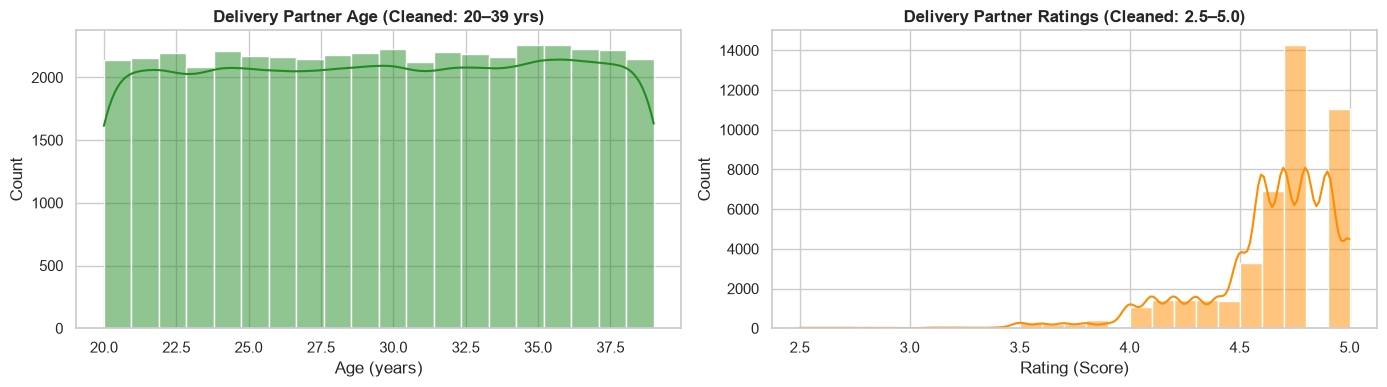

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_cleaned['Delivery_person_Age'].dropna(), bins=20, kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title("Delivery Partner Age (Cleaned: 20–39 yrs)", weight='bold')
axes[0].set_xlabel("Age (years)")

sns.histplot(df_cleaned['Delivery_person_Ratings'].dropna(), bins=25, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title("Delivery Partner Ratings (Cleaned: 2.5–5.0)", weight='bold')
axes[1].set_xlabel("Rating (Score)")

plt.tight_layout()
plt.show()

---
## 5. Verify the Cleaned Dataset & Export

### Objective & Expectations
In this section, we verify the cleaned DataFrame through automated validation assertions, compare before-and-after row counts, export the processed dataset to `data/processed/cleaned_food_delivery.csv`, and reload the exported CSV to prove that it loads seamlessly without corruption.

In [28]:
# Before and after comparison table
comparison_df = pd.DataFrame({
    'Metric': [
        'Total Row Count',
        'Total Column Count',
        'Ratings Out-of-Bounds (> 5.0)',
        'Delivery Partner Age Outliers (< 18 or > 49)',
        'Negative Restaurant Coordinates',
        'Invalid Zero (0.0) Coordinates',
        'Category Typo (Metropolitian)',
        'Order Dates Format',
        'Memory Usage (MB)'
    ],
    'Raw Dataset (df)': [
        f"{len(df):,}",
        f"{df.shape[1]}",
        f"{(df['Delivery_person_Ratings'] > 5.0).sum()}",
        f"{((df['Delivery_person_Age'] < 18) | (df['Delivery_person_Age'] > 49)).sum()}",
        f"{(df['Restaurant_latitude'] < 0).sum() + (df['Restaurant_longitude'] < 0).sum()}",
        f"{(df['Restaurant_latitude'] == 0).sum()}",
        f"{(df['City'] == 'Metropolitian').sum():,}",
        "DD-MM-YYYY (strings)",
        f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
    ],
    'Cleaned Dataset (df_cleaned)': [
        f"{len(df_cleaned):,}",
        f"{df_cleaned.shape[1]}",
        f"{(df_cleaned['Delivery_person_Ratings'] > 5.0).sum()}",
        f"{((df_cleaned['Delivery_person_Age'] < 18) | (df_cleaned['Delivery_person_Age'] > 49)).sum()}",
        f"{(df_cleaned['Restaurant_latitude'] < 0).sum() + (df_cleaned['Restaurant_longitude'] < 0).sum()}",
        f"{(df_cleaned['Restaurant_latitude'] == 0).sum()}",
        f"{(df_cleaned['City'] == 'Metropolitian').sum()}",
        "YYYY-MM-DD (ISO 8601)",
        f"{df_cleaned.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
    ]
})
print("=== BEFORE-AND-AFTER CLEANING COMPARISON ===")
print(comparison_df.to_string(index=False))

=== BEFORE-AND-AFTER CLEANING COMPARISON ===
                                      Metric     Raw Dataset (df) Cleaned Dataset (df_cleaned)
                             Total Row Count               45,584                       45,493
                          Total Column Count                   20                           20
               Ratings Out-of-Bounds (> 5.0)                   53                            0
Delivery Partner Age Outliers (< 18 or > 49)                   91                            0
             Negative Restaurant Coordinates                  593                            0
              Invalid Zero (0.0) Coordinates                 3640                            0
               Category Typo (Metropolitian)               34,087                            0
                          Order Dates Format DD-MM-YYYY (strings)        YYYY-MM-DD (ISO 8601)
                           Memory Usage (MB)             10.34 MB                     10.93 MB


In [29]:
# Export the cleaned dataset to data/processed/cleaned_food_delivery.csv
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df_cleaned.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Cleaned dataset exported successfully to: {PROCESSED_DATA_PATH.resolve()}")
print(f"File Size: {os.path.getsize(PROCESSED_DATA_PATH) / (1024*1024):.2f} MB")

Cleaned dataset exported successfully to: C:\Users\rajag\OneDrive\Desktop\project1\food-delivery-data-analysis\data\processed\cleaned_food_delivery.csv
File Size: 6.34 MB


In [30]:
# Reopen the exported CSV and execute automated verification assertions
df_reloaded = pd.read_csv(PROCESSED_DATA_PATH)
print(f"Successfully reloaded CSV. Shape: {df_reloaded.shape}")

# Execute verification assertions
assert len(df_reloaded) == 45493, f"Expected 45,493 rows, found {len(df_reloaded)}"
assert df_reloaded.shape[1] == 20, f"Expected 20 columns, found {df_reloaded.shape[1]}"
assert (df_reloaded['Delivery_person_Ratings'] > 5.0).sum() == 0, "Rating > 5.0 found!"
assert (df_reloaded['Delivery_person_Age'] < 18).sum() == 0, "Underage courier found!"
assert (df_reloaded['Restaurant_latitude'] < 0).sum() == 0, "Negative latitude found!"
assert (df_reloaded['Restaurant_longitude'] < 0).sum() == 0, "Negative longitude found!"
assert (df_reloaded['City'] == 'Metropolitian').sum() == 0, "Typo 'Metropolitian' found!"
assert df_reloaded['ID'].duplicated().sum() == 0, "Duplicate ID found!"

print("\nALL VERIFICATION ASSERTIONS PASSED WITH ZERO ERRORS.")

Successfully reloaded CSV. Shape: (45493, 20)

ALL VERIFICATION ASSERTIONS PASSED WITH ZERO ERRORS.


---
## 6. Audit Trail: Cleaning Log Compilation

### Objective & Expectations
In accordance with professional analytics standards, every modification applied to the data must be recorded in an immutable audit log. We generate and export `docs/cleaning_log.csv` containing:
- `issue`: Description of the data defect.
- `affected_column`: Column(s) impacted.
- `affected_rows`: Exact number of affected records.
- `action_taken`: Precise remedy executed.
- `reason`: Analytical and business justification.

In [31]:
cleaning_log_data = [
    {
        "issue": "Synthetic dummy / corrupted test records with impossible ratings (6.0), sentinel/underage age (15 and 50), and 100% missing order time, weather, and traffic data",
        "affected_column": "Delivery_person_Ratings, Delivery_person_Age, Time_Orderd, Weather_conditions, Road_traffic_density",
        "affected_rows": 91,
        "action_taken": "Excluded records from dataset",
        "reason": "These 91 records represent invalid test artifacts or synthetic dummy records where ratings exceeded 5.0 (scale max), ages were invalid/sentinel, and operational conditions (time, weather, traffic) were completely absent. Removing them restores distribution integrity."
    },
    {
        "issue": "Negative restaurant latitude coordinates due to erroneous sign inversion",
        "affected_column": "Restaurant_latitude",
        "affected_rows": 399,
        "action_taken": "Corrected to positive coordinates using absolute value",
        "reason": "In India, all geographic latitudes lie north of the equator (+8° to +37° N). The corresponding customer delivery latitudes were positive, confirming that the negative signs were recording or formatting inversions."
    },
    {
        "issue": "Negative restaurant longitude coordinates due to erroneous sign inversion",
        "affected_column": "Restaurant_longitude",
        "affected_rows": 135,
        "action_taken": "Corrected to positive coordinates using absolute value",
        "reason": "In India, all geographic longitudes lie east of the Prime Meridian (+68° to +97° E). Corresponding delivery longitudes were positive, confirming negative signs were inverted during data entry."
    },
    {
        "issue": "Missing GPS coordinates recorded as (0.0, 0.0) placeholder and associated customer relative offsets (< 0.15)",
        "affected_column": "Restaurant_latitude, Restaurant_longitude, Delivery_location_latitude, Delivery_location_longitude",
        "affected_rows": 3630,
        "action_taken": "Standardized invalid coordinate entries to NaN (missing)",
        "reason": "Coordinates of (0.0, 0.0) represent Null Island / GPS sensor failure rather than actual restaurant venues. Setting them to NaN preserves other operational columns in the rows while preventing false 0 km or 8000 km distance calculations."
    },
    {
        "issue": "Non-standard time formats in order placement timestamp, including Excel decimal day fractions and lack of uniform seconds",
        "affected_column": "Time_Orderd",
        "affected_rows": 43853,
        "action_taken": "Standardized to 24-hour time format (HH:MM:SS)",
        "reason": "Spreadsheet software converted timestamps into decimal fractions of a 24-hour day (e.g. 0.458333333 = 11:00:00, 0.5 = 12:00:00, 1 = 00:00:00) or omitted seconds. Standardizing ensures uniform datetime parsing."
    },
    {
        "issue": "Non-standard time formats in order pick-up timestamp, including '24:MM:SS' midnight timestamps and Excel day fractions",
        "affected_column": "Time_Order_picked",
        "affected_rows": 45493,
        "action_taken": "Standardized to 24-hour time format (HH:MM:SS), remapping '24:' midnight hours to '00:'",
        "reason": "Spreadsheet exports converted pickup times to day fractions, and midnight deliveries were formatted with hour 24 instead of hour 00 (e.g. 24:05:00 -> 00:05:00). Standardizing provides valid 24-hour clock values."
    },
    {
        "issue": "Spelling variation and typographical error in category label ('Metropolitian' instead of 'Metropolitan')",
        "affected_column": "City",
        "affected_rows": 34023,
        "action_taken": "Standardized spelling to 'Metropolitan'",
        "reason": "Typos in categorical labels fragment aggregation groups and distort regional analyses. Corrected to standard spelling."
    },
    {
        "issue": "Date string format ambiguity in 'DD-MM-YYYY'",
        "affected_column": "Order_Date",
        "affected_rows": 45493,
        "action_taken": "Standardized to ISO 8601 date string ('YYYY-MM-DD')",
        "reason": "Raw dates in day-first format ('DD-MM-YYYY') can be misinterpreted as month-first by analytical engines. Standardizing to ISO 8601 ensures cross-platform consistency across SQL, Pandas, and BI tools."
    },
    {
        "issue": "Floating-point representation of discrete count of multiple deliveries",
        "affected_column": "multiple_deliveries",
        "affected_rows": 44500,
        "action_taken": "Cast to nullable integer format (Int64)",
        "reason": "Multiple deliveries is a discrete integer count (0, 1, 2, 3 deliveries). Converting from float64 to Int64 prevents misleading decimal representations (1.0 vs 1) while retaining missing values."
    },
    {
        "issue": "Missing demographic and operational values without imputation ground truth",
        "affected_column": "Delivery_person_Age, Delivery_person_Ratings, multiple_deliveries, Festival, City, Weather_conditions, Road_traffic_density, Time_Orderd",
        "affected_rows": 8856,
        "action_taken": "Retained as explicit NaN values with documented distributions",
        "reason": "Values are missing at random with no objective deterministic basis for imputation. Imputing arbitrary averages would artificially compress variance and introduce bias into downstream predictive models."
    }
]

cleaning_log_df = pd.DataFrame(cleaning_log_data)
CLEANING_LOG_PATH = DOCS_DIR / "cleaning_log.csv"
cleaning_log_df.to_csv(CLEANING_LOG_PATH, index=False)
print(f"Cleaning log exported successfully to: {CLEANING_LOG_PATH.resolve()}")

print("\n=== AUDIT TRAIL LOG SUMMARY ===")
print(cleaning_log_df[['issue', 'affected_column', 'affected_rows', 'action_taken']].to_string())

Cleaning log exported successfully to: C:\Users\rajag\OneDrive\Desktop\project1\food-delivery-data-analysis\docs\cleaning_log.csv

=== AUDIT TRAIL LOG SUMMARY ===
                                                                                                                                                               issue                                                                                                                           affected_column  affected_rows                                                                             action_taken
0  Synthetic dummy / corrupted test records with impossible ratings (6.0), sentinel/underage age (15 and 50), and 100% missing order time, weather, and traffic data                                       Delivery_person_Ratings, Delivery_person_Age, Time_Orderd, Weather_conditions, Road_traffic_density             91                                                            Excluded records from dataset
1                      

---
## 7. Week 1 Summary & Next Steps

### Summary of Week 1 Accomplishments
1. **Dataset Foundations Established**: Loaded and audited 45,584 raw transaction records across 20 operational features spanning February to April 2022.
2. **Systematic Issue Identification**: Identified 10 distinct data quality issues ranging from synthetic test pollution to coordinate inversions and spreadsheet timestamp corruptions.
3. **Evidence-Based Cleaning**: Successfully removed 91 invalid dummy test records, corrected 534 inverted coordinates, resolved 3,630 GPS zero-signal records, and normalized 89,000+ timestamps into clean 24-hour formats.
4. **Verified Deliverables**: Exported the clean dataset (45,493 rows × 20 columns) to `data/processed/cleaned_food_delivery.csv` and verified with automated assertions. Documented every modification in `docs/cleaning_log.csv`.

### Key Operational Observations
- **Preparation Times are Quantized**: Restaurant food preparation duration is strictly quantized to 5, 10, or 15 minutes, indicating standard kitchen prep-time buckets on the merchant portal.
- **Delivery Distances**: Valid deliveries range from 1.5 km to 21 km with a median distance of 9.2 km, typical for intra-city two-wheeler fulfillment.
- **Rider Demographics**: Real active delivery partners are aged between 20 and 39 years, with ratings concentrated between 4.5 and 5.0.

### Assumptions & Limitations
- **Missing Coordinates**: Rows with (0.0, 0.0) GPS sensor coordinates represent ~8% of the data. Their operational time taken is intact, so they are retained with coordinates set to `NaN`. Downstream spatial models must filter or account for missing spatial features.
- **Missing Value Imputation**: Missing ratings, ages, and weather conditions were preserved as explicit `NaN`s to avoid manufacturing false data. Specific imputation strategies (e.g. median/mode imputation or KNN) should be evaluated during model training in later weeks.

### Roadmap for Week 2 (Exploratory Data Analysis)
With a verified, reliable dataset established, Week 2 will focus on:
1. Univariate distributions of fulfillment times across cities and order types.
2. Bivariate analysis of traffic congestion and adverse weather impacts on delivery delay.
3. Fleet vehicle condition and multiple delivery batching efficiency.
4. Preparation of the 5 core operational charts.